# TP : projections climatiques
## Estimation des incertitudes climatiques dans le cas des projections de la température globale

Enora Cariou (enora.cariou@meteo.fr)

Votre notebook, renommé suivant le format `notebook_VOTRE_NOM_DE_FAMILLE.ipynb` est à déposer sur l'espace suivant : https://drive.google.com/drive/folders/1aHuT1AImUva7QmAFISaYpErH-HNZUXWW?usp=drive_link

### Rappels du cours sur les projections futures et incertitudes

**Rappel de terminologie :**

- Climat = état moyen + variabilité climatique
- Variabilité climatique = variabilité interne + forçages externes
- Forçages externes = forçages naturels + forçages anthropiques
- Variabilité interne + forçages naturels = variabilité naturelle

La précision des projections climatiques fournies par les modèles de climat dépend de **l'incertitude climatique** qui est fonction de trois facteurs :
1. le scénario d'émissions des gaz à effet de serre (GES) et des aérosols anthropiques, c'est-à-dire des *forçaces externes* d'origine anthropique, dont la concentration va être modifié au cours des prochaines décennies : **<span style="color: green;">l'incertitude scénario</span>**
2. **<span style="color: orange;">la variabilité interne</span>** du système climatique
3. l'erreur de modélisation de la variabilité climatique : **<span style="color: blue;">l'incertitude modèle</span>**

L'incertitude scénario due aux forçages anthropiques qui modifient l'équilibre radiatif du système climatique est modulée par le choix d'une trajectoire socio-économique plus ou moins émettrice de GES.

L'incertitude due à la variabilité interne englobe les fluctuations climatiques qui se produisent naturellement en l'absence de toute modification des forçages radiatifs.

L'incertitude du modèle quantifie l'erreur de modélisation dans la simulation des réponses climatiques aux forçages naturels (activité solaire, aérosols naturels etc.) et anthropiques.

#### L'amplitude des incertitudes dépend de l'échelle spatio-temporelle

Pour un scénario d'émissions donné, nous savons qu'à l'échelle locale, l'incertitude liée à la variabilité interne est généralement plus grande que l'incertitude modèle à une échéance décennale. A mesure que l'échelle spatio-temporelle s'agrandit, la variabilité interne locale est moyennée et est réduite laissant apparaître la réponse du système aux forçages externes anthropiques.

Ainsi, plus l'échelle spatio-temporelle devient grande, plus l'incertitude due à la variabilité interne diminue et plus l'incertitude modèle augmente, si bien que dans le cas des projections de la température globale, la seconde devient prédominante devant la première :

![alt text](data/frac_var.png "Title")

### Objectifs du TP :
- Estimer les incertitudes associées aux projections de températures, en estimant les contributions :
    - de la variabilité interne
    - de la trajectoire socio-économique future (scénario)
    - des biais des modèles
- Quantifier la sensibilité de ces incertitudes à l'échelle spatio-temporelle

### Données à disposition :
Température moyenne à 2 m de 1850 à 2100 pour 20 modèles de climat, et
3 scénarios socio-économiques (Shared Socio-Economic Pathway): SSP1-2.6, SSP2-4.5, SSP5-8.5.
Toutes les données correspondantes sont préparées dans les fichiers sous le format ``T_*ssp*.asc``.
On étudie le champ de température moyennée sur le globe, et sur la France en été (moyenne JJA, Juin-Juillet-Août) et en hiver (moyenne DJF, Décembre-Janvier-Février).

### Chargement/installation des librairies python

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Chargement/installation des librairies python

La cellule suivante contient les librairies à charger, elle n'est pas à modifier.

***Si l'execution de la cellule ne fonctionne pas:***
- Installer les packages manquant en tapant dans un terminal, sans être connecté au VPN Météo-France :

`pip install --user le_package_en_question`

- Redémarrer le noyau dans le menu ci-dessus.

In [3]:
# Set the path where data are located
path_data = "./data/"

# load ascii files

# Global temperature
T_glo_ssp26 = pd.read_csv(path_data+"T_Glo_ANN_ssp126.asc", sep=" ")-273.15
T_glo_ssp45 = pd.read_csv(path_data+"T_Glo_ANN_ssp245.asc", sep=" ")-273.15
T_glo_ssp85 = pd.read_csv(path_data+"T_Glo_ANN_ssp585.asc", sep=" ")-273.15

# Temp over France in JJA
T_fr_jja_ssp26 = pd.read_csv(path_data+"T_fr_JJA_ssp126.asc", sep=" ")-273.15
T_fr_jja_ssp45 = pd.read_csv(path_data+"T_fr_JJA_ssp245.asc", sep=" ")-273.15
T_fr_jja_ssp85 = pd.read_csv(path_data+"T_fr_JJA_ssp585.asc", sep=" ")-273.15

# Temp over France in DJF
T_fr_djf_ssp26 = pd.read_csv(path_data+"T_fr_DJF_ssp126.asc", sep=" ")-273.15
T_fr_djf_ssp45 = pd.read_csv(path_data+"T_fr_DJF_ssp245.asc", sep=" ")-273.15
T_fr_djf_ssp85 = pd.read_csv(path_data+"T_fr_DJF_ssp585.asc", sep=" ")-273.15


Puis on vérifie que les variables chargés ont bien les bonnes coordonnées et dimensions.

In [4]:
# Verify fields dimensions
T_ssp26 = T_fr_jja_ssp26
T_ssp45 = T_fr_jja_ssp45
T_ssp85 = T_fr_jja_ssp85

T_ssp26

,ACCESS-CM2,MPI-ESM1-2-HR,UKESM1-0-LL,ACCESS-ESM1-5,CESM2-WACCM,INM-CM4-8,MPI-ESM1-2-LR,FGOALS-f3-L,INM-CM5-0,MRI-ESM2-0,CNRM-CM6-1-HR,IPSL-CM6A-LR,NorESM2-LM,CNRM-CM6-1,GISS-E2-1-G,MIROC6,NorESM2-MM,CNRM-ESM2-1,HadGEM3-GC31-LL,MIROC-ES2L
1850,18.343835,17.964136,19.484033,20.766260,19.199731,22.748376,17.185510,18.097681,20.480035,17.851770,18.423242,16.682703,19.053400,18.784113,16.845026,22.533441,19.415369,19.157129,16.610284,18.713007
1851,18.496362,18.227380,19.604211,18.256036,18.965082,22.355096,16.262964,18.695367,20.722437,20.004602,17.154077,18.538965,19.456567,18.724207,16.386102,20.370905,16.925775,20.451929,19.429468,20.002618
1852,16.654443,17.901971,16.193292,18.730951,18.742059,21.032983,17.778986,18.110376,23.109369,18.882593,17.351160,16.988000,18.111230,16.839166,18.041650,21.786188,19.721429,18.829645,17.520288,20.230035
1853,18.338953,18.142847,19.361505,19.308984,17.439264,23.536371,17.799158,18.389368,22.628046,18.475427,15.832788,17.382532,20.314172,19.578851,16.489160,21.814264,20.293115,19.069696,15.660303,20.532709
1854,17.368250,17.985284,18.024011,21.391321,17.731622,23.248682,17.176965,17.854639,20.056818,17.214441,19.732416,17.542566,18.118677,17.914240,16.543024,20.714105,18.010706,17.949396,17.274438,20.167749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,21.922418,18.779199,19.710657,22.553308,21.923853,23.038110,17.255701,20.078271,24.938898,20.584039,19.908777,21.369104,21.156000,21.281244,17.986627,23.084467,22.307153,22.057733,20.266351,22.097467
2097,21.008173,18.845514,21.028772,23.104669,22.770013,23.316797,20.003229,19.660699,20.151361,19.096490,19.803827,22.416498,22.776575,20.374902,19.633356,22.493311,19.687128,19.710840,21.457483,21.037225
2098,20.827203,20.796320,21.093774,24.153162,21.732080,23.436334,18.922571,18.940790,22.578516,18.572046,20.588068,20.578455,21.736261,22.132898,20.142694,23.122400,22.915247,21.598077,21.808038,22.466577
2099,20.411676,19.236200,22.071436,22.460535,20.942194,24.874963,17.048059,19.340021,23.750635,20.832178,21.817957,21.864252,22.449945,19.844843,18.500970,22.792139,19.291467,21.906885,21.399377,21.901727


In [5]:
# Get dimension numbers and names
years = T_ssp26.index.values
models = T_ssp26.columns.values
nyr = len(years)
nmod = len(models)

On peut maintenant commencer à estimer l'incertitude dans notre ensemble !

### Séparation de la variabilité interne et de la réponse aux forçages externes :

La variabilité de la température globale est supposée décomposable comme combinaison linéaire d’une variabilité forcée par les forçages externes (gaz à effet de serre, aérosols, cycle solaire) et d’une variabilité naturelle, intrinsèque au système climatique (variabilité interne).

Les projections de température $X$ pour chaque modèle $m$, scénario $s$ et échéance $t$ peuvent alors s’écrire de la manière suivante :

$$ X(t, m, s) = x(t, m, s) + \epsilon(t, m, s) $$

- La réponse aux forçages externes est notée $x$. Elle correspond à un lissage de $X$ sur l’ensemble de la période projetée, de telle sorte à filtrer la variabilité interne interannuelle au premier ordre.
- Le résidu est noté $\epsilon$ et correspond à la variabilité interne.

Voyons d'abord à quoi ressemble la série temporelle brute de la température en France en JJA pour le modèle CNRM-CM6-1 pour les trois scénarios envisagés.

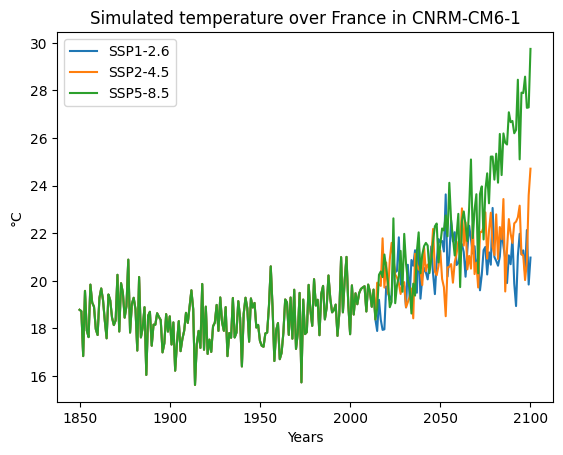

In [7]:
# Plot
plt.plot(T_ssp26["CNRM-CM6-1"], label='SSP1-2.6')
plt.plot(T_ssp45["CNRM-CM6-1"], label='SSP2-4.5')
plt.plot(T_ssp85["CNRM-CM6-1"], label='SSP5-8.5')
plt.title("Simulated temperature over France in CNRM-CM6-1")
plt.xlabel('Years') 
plt.ylabel('°C')
plt.legend()

Pour chacune de ces trois séries de $X$, la variabilité interne $\epsilon$ se superpose à une réponse de la température aux forçages externes anthropiques $x$, qui se matérialise par une tendance croissante.

#### Estimation de la réponse aux forçages externes

L'étape suivante consiste à isoler $x$ de $\epsilon$. Pour cela, nous estimons $x$ en approximant $X$ par un polynôme d'ordre 2 (= tendance quadratique) pour lisser la série temporelle.

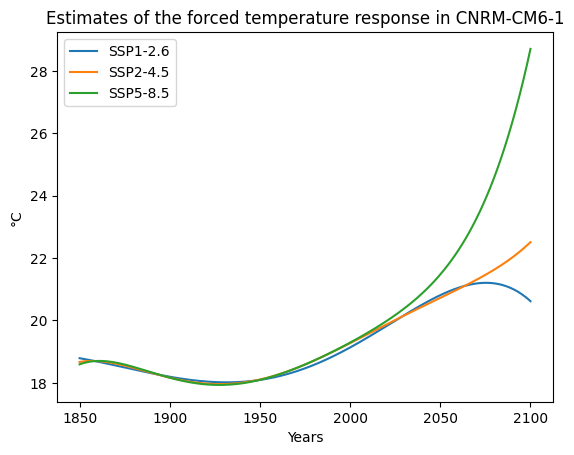

In [8]:
# Fit quadratic parameters on raw time series
deg =5
coef_T_ssp26 = np.polyfit(years,T_ssp26,deg)
coef_T_ssp45 = np.polyfit(years,T_ssp45,deg)
coef_T_ssp85 = np.polyfit(years,T_ssp85,deg)

# initialize the forced response
ant_T_ssp26 = T_ssp26.copy()
ant_T_ssp45 = T_ssp45.copy()
ant_T_ssp85 = T_ssp85.copy()

# compute the time series for each model
for imod in range(nmod):
    ant_T_ssp26[models[imod]] = np.polyval(coef_T_ssp26[:,imod], years)
    ant_T_ssp45[models[imod]] = np.polyval(coef_T_ssp45[:,imod], years)
    ant_T_ssp85[models[imod]] = np.polyval(coef_T_ssp85[:,imod], years)

# Plot for CNRM-CM6
plt.plot(ant_T_ssp26["CNRM-CM6-1"], label='SSP1-2.6')
plt.plot(ant_T_ssp45["CNRM-CM6-1"], label='SSP2-4.5')
plt.plot(ant_T_ssp85["CNRM-CM6-1"], label='SSP5-8.5')
plt.title("Estimates of the forced temperature response in CNRM-CM6-1")
plt.xlabel('Years') 
plt.ylabel('°C')
plt.legend()


### Question

Ce lissage de $X$ vous parait-il correct ? Pourquoi ?


<div style="background:rgb(230,255,230); padding:3px;">    
Votre réponse ici
</div>

Choisissez un lissage adapté pour continuer le TP

#### Estimation de la variabilité interne

Maintenant que l'on a isolé la réponse $x$, la variabilité interne $\epsilon$ se déduit facilement en calculant la différence entre $X$ et $x$.

Compléter le code afin de calculer la variabilité interne pour chaque scénario

In [12]:
# get internal variability
iv_T_ssp26 = T_ssp26.loc[1850:2100] - ant_T_ssp26.loc[1850:2100]
iv_T_ssp45 = T_ssp45.loc[1850:2100] - ant_T_ssp45.loc[1850:2100]
iv_T_ssp85 = T_ssp85.loc[1850:2100] - ant_T_ssp85.loc[1850:2100]

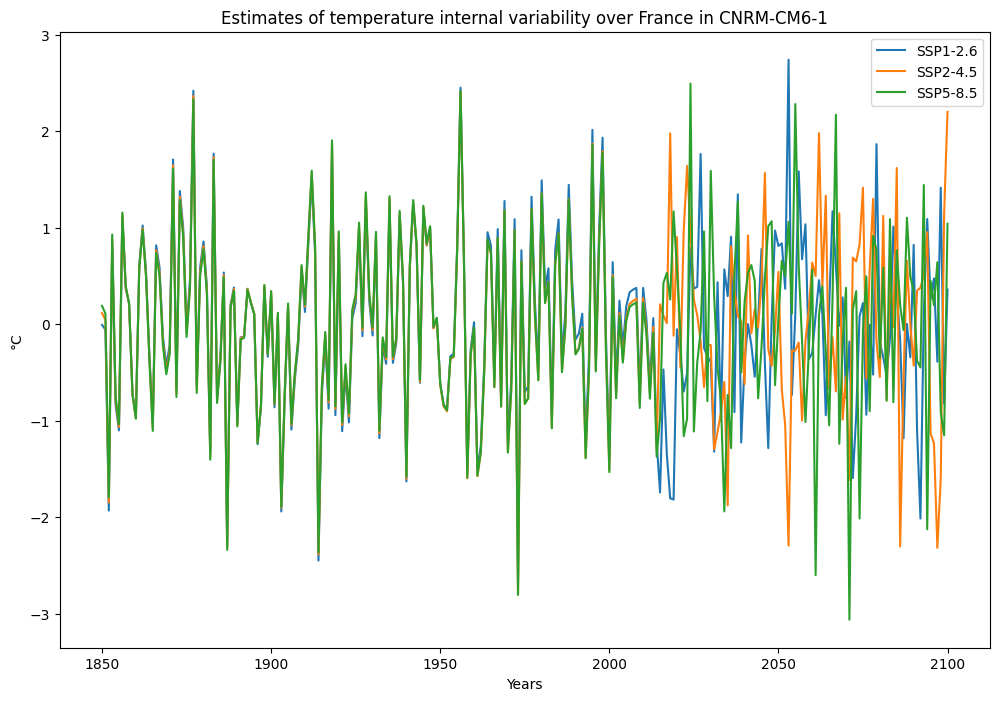

In [13]:
# plot for CNRM-CM6 (historical period)
plt.figure(figsize=(12,8))
plt.plot(iv_T_ssp26["CNRM-CM6-1"].loc[1850:2100], label='SSP1-2.6')
plt.plot(iv_T_ssp45["CNRM-CM6-1"].loc[1850:2100], label='SSP2-4.5')
plt.plot(iv_T_ssp85["CNRM-CM6-1"].loc[1850:2100], label='SSP5-8.5')
plt.title("Estimates of temperature internal variability over France in CNRM-CM6-1")
plt.xlabel('Years') 
plt.ylabel('°C')
plt.legend()


### Questions

- Qu'est-ce qui expliquerait les fluctuations de température sur la France entre 1850 et 2014 (période historique) constatées sur ces courbes ?
- Est-il possible de correctement estimer la variabilité interne sur cette période ?
- Si vous aviez un modèle de climat à disposition, que feriez-vous pour obtenir une meilleure estimation de la variabilité interne ?

<div style="background:rgb(230,255,230); padding:3px;">    
Votre réponse ici
</div>

### Estimation de l'incertitude climatique

Nous reprenons la décomposition en sources d'incertitudes formulée au début du TP.

L’incertitude $\color{orange}{V}$ due à la variabilité interne est considérée ici comme constante (indépendante de $t$) et indépendante du scénario d'émission (indépendante de $s$). Elle est définie à partir de la moyenne multi-modèles de la variance de $\epsilon$ :

$$\color{orange}{V = \frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} \textrm{Var}_{t,s}[\epsilon(m)]}$$

où $N_{mod}$ correspond au nombre de modèles.

Aide python

- Calcul de la variance https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.var.html

- Calcul de la moyenne https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html

In [14]:
# Concatenate the three scenarios
iv_T = pd.concat([iv_T_ssp26,iv_T_ssp45,iv_T_ssp85])

# Compute the variance across the scenarios and the years
iv_unc_variance = iv_T.var(axis=0)

# Get the multi-model mean
iv_unc = iv_unc_variance.mean()
iv_unc

1.0824149218864765

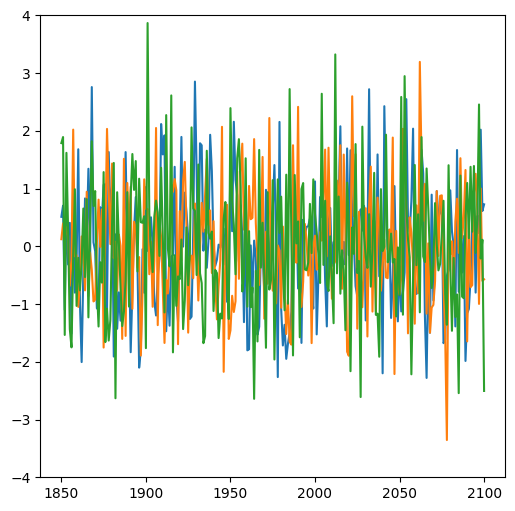

In [50]:
plt.figure(figsize=(6,6))
plt.plot(iv_T_ssp85['ACCESS-CM2'])
plt.plot(iv_T_ssp85['MPI-ESM1-2-HR'])
plt.plot(iv_T_ssp85['UKESM1-0-LL'])
plt.ylim(-4,4)
plt.savefig('/home/carioue/Documents/TPs/TP_projection_clim_IENM2/ssp85.pdf')

L’incertitude modèle $\color{blue}{M}$ repose sur la dispersion des réponses $x$ simulées par les différents modèles disponibles. Elle est définie pour chaque échéance $t$ :

$$\color{blue}{M(t) = \frac{1}{N_{scen}} \sum_{s=1}^{N_{scen}} \textrm{Var}_{m}[x(t,s)]}$$

où $N_{scen}$ désigne le nombre de scénarios.

In [14]:
# Model uncertainty for each scenario: variance across the models
mod_unc_T_ssp26 = ant_T_ssp26.var(axis=1)
mod_unc_T_ssp45 = ant_T_ssp45.var(axis=1)
mod_unc_T_ssp85 = ant_T_ssp85.var(axis=1)

# Mean across the scenarios
mod_unc = 1/3 * (mod_unc_T_ssp26+mod_unc_T_ssp45+mod_unc_T_ssp85)
mod_unc

1850    2.015824
1851    1.994119
1852    1.973952
1853    1.955221
1854    1.937829
          ...   
2096    2.936060
2097    2.971823
2098    3.009508
2099    3.049250
2100    3.091191
Length: 251, dtype: float64

L’incertitude scénario $\color{green}{S}$ est quant à elle définie comme la variance entre les scénarios des moyennes multi-modèles de $x$. Elle dépend de $t$ :

$$\color{green}{S(t) = \textrm{Var}_{scen}\left[\frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} x(t,m)\right]}$$

In [27]:
# Scenario uncertainty for each year: multi-model mean across the forced response
mod_avg_T_ssp26 = ant_T_ssp26.mean(axis=1)
mod_avg_T_ssp45 = ant_T_ssp45.mean(axis=1)
mod_avg_T_ssp85 = ant_T_ssp85.mean(axis=1)

# Concatenate the three scenarios
mod_avg_T = pd.concat([mod_avg_T_ssp26,mod_avg_T_ssp45,mod_avg_T_ssp85],axis=1,keys=['SSP26','SSP45','SSP85'])

# Variance across the scenarios
scen_unc = mod_avg_T.var(axis=1)
scen_unc

1850    0.002033
1851    0.001531
1852    0.001123
1853    0.000796
1854    0.000541
          ...   
2096    7.307705
2097    7.730150
2098    8.173269
2099    8.637900
2100    9.124910
Length: 251, dtype: float64

Les incertitudes sont supposées comme étant additives et n’interagissent pas entre-elles ; l'incertitude totale est alors définie comme la somme $T$ des incertitudes calculées précédemment :
$$ T(t) = \color{orange}{V} + \color{blue}{M(t)} + \color{green}{S(t)}$$

In [119]:
# Compute the total variance
total_unc = iv_unc + mod_unc + scen_unc

### Question

- Tracer l'incertitude total $T$ (enregistrer la figure)

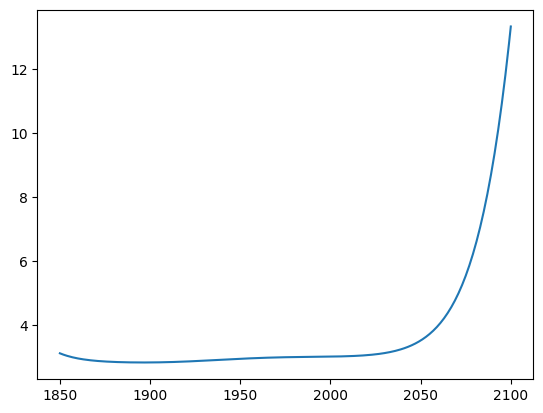

In [120]:
# plot over the projected period
plt.plot(total_unc)

Pour identifier l'importance de chaque source d'incertitude, on peut normaliser chacune d'entre-elles par l'incertitude totale, pour obtenir des pourcentages relatifs d'incertitude.

In [122]:
# Normalize each uncertainty by T
iv_unc_relative = iv_unc/total_unc*100
mod_unc_relative = mod_unc/total_unc*100
scen_unc_relative = scen_unc/total_unc*100

unc_relative = pd.concat([mod_unc_relative,scen_unc_relative,iv_unc_relative],axis=1,
                         keys=['model uncertainty','scenario uncertainty','internal variability'])

unc_relative


,model uncertainty,scenario uncertainty,internal variability
1850,64.821610,0.059351,35.119039
1851,64.583941,0.044941,35.371118
1852,64.358907,0.033115,35.607978
1853,64.146154,0.023578,35.830269
1854,63.945299,0.016053,36.038648
...,...,...,...
2096,25.886617,64.484282,9.629100
2097,25.181721,65.564102,9.254177
2098,24.499906,66.609223,8.890871
2099,23.841417,67.619436,8.539146


Visuellement, on peut finalement refaire la représentation graphique présentée au début du TP.

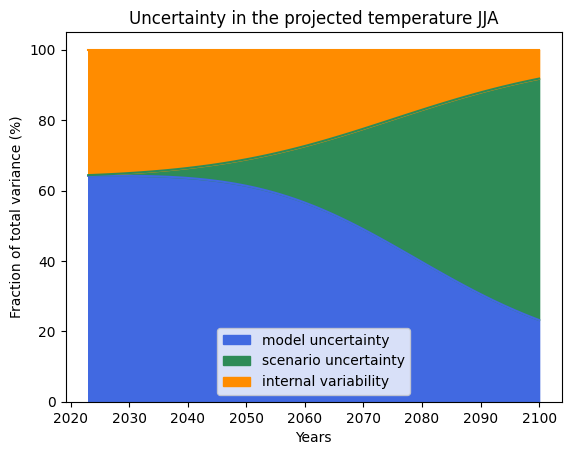

In [123]:
ax = unc_relative.loc[2023:2100].plot(kind='area', stacked=True, color=['royalblue','seagreen','darkorange'],
                                      title='Uncertainty in the projected temperature JJA')

ax.set_ylabel('Fraction of total variance (%)')
ax.set_xlabel('Years')
plt.show()

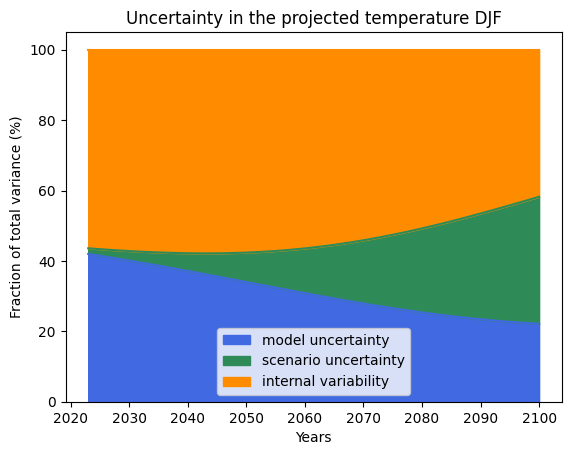

In [32]:
ax = unc_relative.loc[2023:2100].plot(kind='area', stacked=True, color=['royalblue','seagreen','darkorange'],
                                      title='Uncertainty in the projected temperature DJF')

ax.set_ylabel('Fraction of total variance (%)')
ax.set_xlabel('Years')
plt.show()

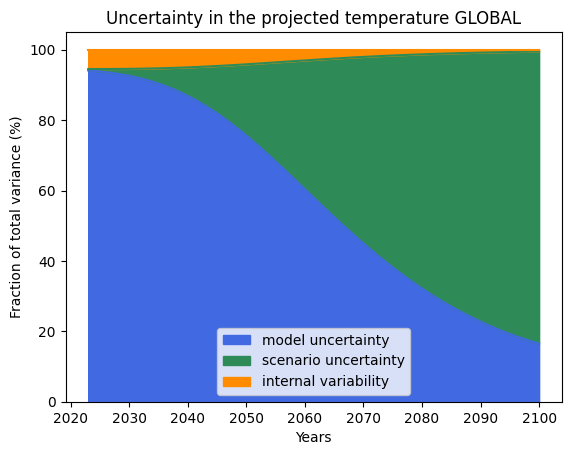

In [79]:
ax = unc_relative.loc[2023:2100].plot(kind='area', stacked=True, color=['royalblue','seagreen','darkorange'],
                                      title='Uncertainty in the projected temperature GLOBAL')

ax.set_ylabel('Fraction of total variance (%)')
ax.set_xlabel('Years')
plt.show()

### Question

Enregistrer la figure ci-dessus, et faîtes le même exercice d'estimation de l'incertitude climatique pour :
- la température en France en DJF
- la température annuelle globale (moyenne planétaire)

Quelles sont les différences avec l'incertitude associée à la température en France en JJA ? Comment les expliquez-vous ?

Commenter les différences entre les formes des courbes de l'incertitude totale T en France JJA et DJF. Comment l'expliquez-vous?

Votre réponse ici